In [87]:
from pathlib import Path

# Current project directory
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Check both possible dataset locations
dataset_candidates = [
    PROJECT_DIR / "data" / "training_text.txt",
    PROJECT_DIR / "data" / "processed" / "training_text.txt",
]

print("Project directory:", PROJECT_DIR.resolve())

for path in dataset_candidates:
    print(f"{path.relative_to(PROJECT_DIR)}: {'FOUND' if path.is_file() else 'NOT FOUND'}")


Project directory: /Users/vijaypatidar/vijay/Anshul/NextWord pred
data/training_text.txt: FOUND
data/processed/training_text.txt: NOT FOUND


In [88]:

from pathlib import Path

dataset_path = PROJECT_DIR / "data" / "training_text.txt"

# Read the original text without modifying it
with open(dataset_path, "r", encoding="utf-8") as file:
    raw_text = file.read()

print("Dataset loaded successfully!")
print("Data type:", type(raw_text))
print("Total characters:", len(raw_text))
print("\nFirst 1000 characters:\n")
print(repr(raw_text[:1000]))


Dataset loaded successfully!
Data type: <class 'str'>
Total characters: 61652

First 1000 characters:

'## Artificial Intelligence\n\nArtificial intelligence is a field of computer science that builds systems capable of performing tasks associated with human intelligence. These tasks include understanding language, recognizing images, planning actions, solving problems, and learning from experience. An AI system uses data, algorithms, and computing resources to produce useful outputs. The quality of an AI system depends on the problem definition, the data used, the model architecture, and the way the system is evaluated.\n\nArtificial intelligence is not a single algorithm. It includes search, planning, symbolic reasoning, machine learning, deep learning, knowledge representation, and natural language processing. Some systems follow explicit rules, while others learn statistical patterns from examples. A practical AI application often combines several methods. For example, a customer s

In [89]:

# 1. Count lines
lines = raw_text.splitlines()

# 2. Split text into paragraphs using blank lines
paragraphs = [
    paragraph.strip()
    for paragraph in raw_text.split("\n\n")
    if paragraph.strip()
]

# 3. Count whitespace-separated words
words = raw_text.split()

print("Total characters:", len(raw_text))
print("Total lines:", len(lines))
print("Total paragraphs:", len(paragraphs))
print("Total words:", len(words))

print("\nFirst 5 lines:")
for line in lines[:5]:
    print(repr(line))

print("\nFirst 3 paragraphs:")
for paragraph in paragraphs[:3]:
    print(repr(paragraph[:200]))


Total characters: 61652
Total lines: 301
Total paragraphs: 147
Total words: 8543

First 5 lines:
'## Artificial Intelligence'
''
'Artificial intelligence is a field of computer science that builds systems capable of performing tasks associated with human intelligence. These tasks include understanding language, recognizing images, planning actions, solving problems, and learning from experience. An AI system uses data, algorithms, and computing resources to produce useful outputs. The quality of an AI system depends on the problem definition, the data used, the model architecture, and the way the system is evaluated.'
''
'Artificial intelligence is not a single algorithm. It includes search, planning, symbolic reasoning, machine learning, deep learning, knowledge representation, and natural language processing. Some systems follow explicit rules, while others learn statistical patterns from examples. A practical AI application often combines several methods. For example, a customer sup

In [97]:
print("Current sum value:", sum)
print("Type of sum:", type(sum))

Current sum value: <built-in function sum>
Type of sum: <class 'builtin_function_or_method'>


In [98]:

from collections import Counter

# 1. Count duplicate paragraphs
paragraph_counts = Counter(paragraphs)

duplicate_paragraphs = {
    paragraph: count
    for paragraph, count in paragraph_counts.items()
    if count > 1
}

print("Total paragraphs:", len(paragraphs))
print("Unique paragraphs:", len(paragraph_counts))
print("Duplicate paragraph groups:", len(duplicate_paragraphs))
print(
    "Extra repeated paragraphs:",
    sum(count - 1 for count in duplicate_paragraphs.values())
)

# 2. Inspect word frequencies
word_counts = Counter(words)

print("\nUnique whitespace-separated tokens:", len(word_counts))
print("\nTop 15 most frequent tokens:")

for word, count in word_counts.most_common(15):
    print(f"{word!r}: {count}")

# 3. Inspect vocabulary examples
print("\nFirst 30 unique tokens:")
print(list(word_counts.keys())[:30])


Total paragraphs: 147
Unique paragraphs: 147
Duplicate paragraph groups: 0
Extra repeated paragraphs: 0

Unique whitespace-separated tokens: 2832

Top 15 most frequent tokens:
'and': 305
'the': 226
'a': 217
'should': 149
'can': 140
'to': 120
'be': 90
'model': 87
'A': 82
'is': 67
'of': 67
'or': 61
'that': 60
'in': 54
'may': 53

First 30 unique tokens:
['##', 'Artificial', 'Intelligence', 'intelligence', 'is', 'a', 'field', 'of', 'computer', 'science', 'that', 'builds', 'systems', 'capable', 'performing', 'tasks', 'associated', 'with', 'human', 'intelligence.', 'These', 'include', 'understanding', 'language,', 'recognizing', 'images,', 'planning', 'actions,', 'solving', 'problems,']


In [99]:

# Inspect paragraph lengths and empty content
paragraph_lengths = [len(p.split()) for p in paragraphs]

empty_paragraphs = [
    i for i, p in enumerate(raw_text.split("\n\n"))
    if not p.strip()
]

print("Total non-empty paragraphs:", len(paragraphs))
print("Empty paragraph segments:", len(empty_paragraphs))
print("Shortest paragraph (words):", min(paragraph_lengths))
print("Longest paragraph (words):", max(paragraph_lengths))
print(
    "Average paragraph length (words):",
    round(sum(paragraph_lengths) / len(paragraph_lengths), 2)
)

print("\nShortest paragraph examples:")
for paragraph in sorted(paragraphs, key=lambda p: len(p.split()))[:5]:
    print(repr(paragraph))

Total non-empty paragraphs: 147
Empty paragraph segments: 0
Shortest paragraph (words): 3
Longest paragraph (words): 1546
Average paragraph length (words): 58.12

Shortest paragraph examples:
'## Artificial Intelligence'
'## Machine Learning'
'## Recommendation Systems'
'## Natural Language Processing'
'## Transformers And Llms'


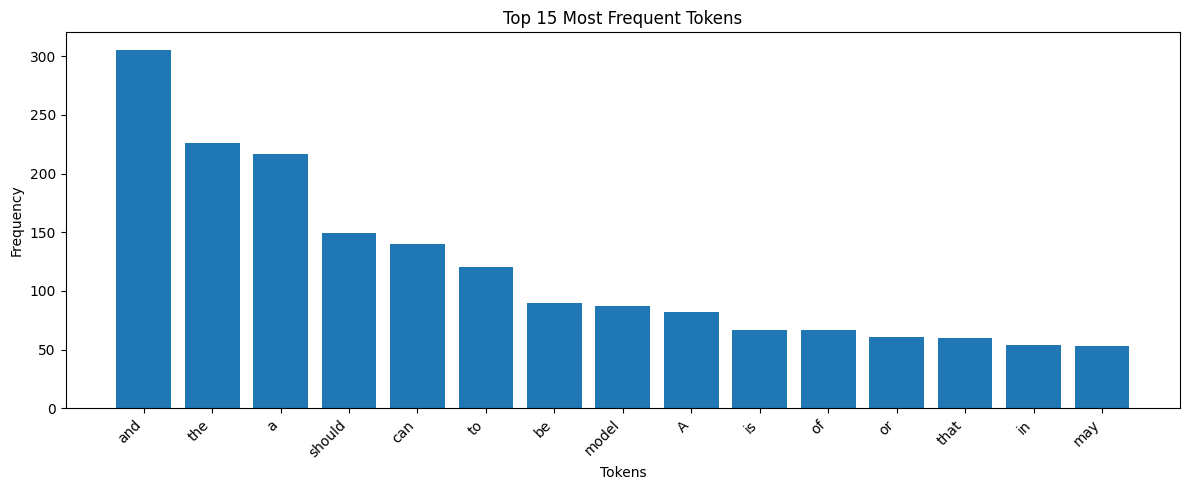

Top 15 frequent tokens:
'and': 305
'the': 226
'a': 217
'should': 149
'can': 140
'to': 120
'be': 90
'model': 87
'A': 82
'is': 67
'of': 67
'or': 61
'that': 60
'in': 54
'may': 53


In [101]:

from collections import Counter
import matplotlib.pyplot as plt

# Calculate token frequencies
word_counts = Counter(raw_text.split())

# Get top 15 frequent tokens
top_words = word_counts.most_common(15)

labels = [word for word, count in top_words]
frequencies = [count for word, count in top_words]

# Create visualization
plt.figure(figsize=(12, 5))
plt.bar(labels, frequencies)

plt.title("Top 15 Most Frequent Tokens")
plt.xlabel("Tokens")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

# Print actual frequency values
print("Top 15 frequent tokens:")
for word, count in top_words:
    print(f"{word!r}: {count}")


In [102]:

# 1. Vocabulary statistics
total_tokens = len(words)
unique_tokens = len(set(words))

print("Total tokens:", total_tokens)
print("Unique tokens:", unique_tokens)

# 2. Vocabulary diversity
vocabulary_ratio = unique_tokens / total_tokens

print("Vocabulary diversity ratio:", round(vocabulary_ratio, 4))

# 3. Most and least frequent tokens
print("\nMost frequent token:")
print(word_counts.most_common(1))

print("\nLeast frequent tokens (frequency = 1):")

rare_words = [
    word for word, count in word_counts.items()
    if count == 1
]

print("Number of rare tokens:", len(rare_words))
print("First 20 rare tokens:", rare_words[:20])

# 4. Corpus suitability summary
print("\n--- Initial Corpus Summary ---")
print("Total words:", total_tokens)
print("Unique tokens:", unique_tokens)
print("Paragraphs:", len(paragraphs))
print("Average paragraph length:", round(
    sum(len(p.split()) for p in paragraphs) / len(paragraphs), 2
))


Total tokens: 8543
Unique tokens: 2832
Vocabulary diversity ratio: 0.3315

Most frequent token:
[('and', 305)]

Least frequent tokens (frequency = 1):
Number of rare tokens: 1713
First 20 rare tokens: ['Intelligence', 'computer', 'capable', 'performing', 'associated', 'intelligence.', 'language,', 'recognizing', 'images,', 'planning', 'solving', 'problems,', 'experience.', 'algorithms,', 'definition,', 'used,', 'way', 'evaluated.', 'algorithm.', 'search,']

--- Initial Corpus Summary ---
Total words: 8543
Unique tokens: 2832
Paragraphs: 147
Average paragraph length: 58.12


In [103]:

# Final dataset verification

print("========== DATASET VERIFICATION ==========")

print("Dataset exists:", dataset_path.is_file())
print("Raw text type:", type(raw_text).__name__)
print("Characters:", len(raw_text))
print("Words:", len(raw_text.split()))
print("Paragraphs:", len(paragraphs))
print("Unique raw tokens:", len(set(raw_text.split())))

print("\nOriginal dataset remains available:", raw_text is not None)

print("\nFirst 100 characters:")
print(repr(raw_text[:100]))


========== DATASET VERIFICATION ==========
Dataset exists: True
Raw text type: str
Characters: 61652
Words: 8543
Paragraphs: 147
Unique raw tokens: 2832

Original dataset remains available: True

First 100 characters:
'## Artificial Intelligence\n\nArtificial intelligence is a field of computer science that builds syste'
